# Figure 1 — Chemical space, cluster representatives, and activity

This notebook creates a three-panel figure for the DRD2 ligand-discovery manuscript.

- **Panel A:** t-SNE projection of compounds using pairwise Tanimoto distances from RDKit path-based fingerprints. The largest clusters are highlighted, the selected cluster is emphasised, and representative compounds are shown as structure callouts.
- **Panel B:** mean measured pIC₅₀ (± SD) across the ten largest clusters, to compare activity between clusters.
- **Panel C:** measured pIC₅₀ values for compounds in the selected cluster, with individual observations and mean ± standard deviation.

The notebook reads the curated compound table, reproduces the project’s Butina clustering at a 0.4 distance cutoff, and calculates a t-SNE embedding for visualisation.

> Cluster labels are zero-based and sorted by size, matching `src/02_clustering.ipynb`. Cluster 6 contains 14 compounds in the project’s current clustering output.


## 1. Configure input and output

The curated CSV is loaded from the repository’s `data/` folder. Cluster IDs and centroid flags are generated using the project’s Butina settings. Required CSV columns:
- `CHEMBLid`: compound identifier
- `pIC50`: measured pIC₅₀ value
- `smiles`: SMILES string
Cluster IDs and centroid flags are generated by the notebook; they are not required in the input CSV.

The repository root is detected from the notebook kernel’s current directory, so input and output paths work whether Jupyter starts in the repository root or `Visualisations/`. The output folder is created automatically.


In [6]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.offsetbox import AnnotationBbox, OffsetImage, TextArea, VPacker
from PIL import Image

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.rdmolops import GetMolFrags
from rdkit.ML.Cluster import Butina
from sklearn.manifold import TSNE

# ---------------- USER SETTINGS ----------------
PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "data/drd2_curated_compounds.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not find the project root from {Path.cwd()}. "
        "Run this notebook from inside the repository."
    )

DATA_PATH = PROJECT_ROOT / "data/drd2_curated_compounds.csv"
OUTPUT_PATH = PROJECT_ROOT / "results/figures/figure1_tsne_clusters.png"
OUTPUT_DPI = 600

DISTANCE_CUTOFF = 0.4
SELECTED_CLUSTER = 6  # Zero-based index of the 14-compound cluster
N_CALLOUTS = 10       # Number of largest clusters to annotate with representative structures
PERPLEXITY = 30
SEED = 22
COLOR_MODE = "theme"  # "theme": blue/orange/grey; "clusters": distinct colours for callout clusters

PIC50_COL = "pIC50"
COMPOUND_COL = "CHEMBLid"
SMILES_COL = "smiles"
CLUSTER_COL = "cluster_id"
CENTROID_COL = "is_centroid"
# ------------------------------------------------

BLUE, ORANGE, GREY, DARK = "#2F7FDB", "#F26B38", "#B8B8B8", "#2B2B2B"

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find input CSV: {DATA_PATH.resolve()}\n"
        "Update DATA_PATH in this cell."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} compounds from {DATA_PATH}")
print("Columns:", df.columns.tolist())
df.head()


Loaded 435 compounds from /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/data/drd2_curated_compounds.csv
Columns: ['CHEMBLid', 'pIC50', 'smiles']


,CHEMBLid,pIC50,smiles
0,CHEMBL567,9.522879,OCCN1CCN(CCCN2c3ccccc3Sc3ccc(Cl)cc32)CC1
1,CHEMBL6004129,9.008774,COc1ccccc1N1CCN(CCCCOc2ccc3c(c2)NC(=O)CO3)CC1
2,CHEMBL5851827,8.974694,O=C1CCc2cc(CCCCN3CCN(c4cccc5sc(F)cc45)CC3)ccc2N1
3,CHEMBL8514,8.958607,CC(C)(C)[C@]1(O)CCN2C[C@H]3c4ccccc4CCc4cccc(c4...
4,CHEMBL3885419,8.958607,CC(C)(C)[C@]1(O)CCN2C[C@@H]3c4ccccc4CCc4cccc(c...


## 2. Validate the table and calculate fingerprints

The code checks the curated activity columns and parses each SMILES string. It generates RDKit path-based fingerprints with `maxPath=5`, then reproduces the project’s Butina clustering and marks each cluster’s first member as its representative.

Cluster IDs are assigned by descending cluster size with zero-based labels, matching `src/02_clustering.ipynb`. The same fingerprints are used for t-SNE.


In [7]:
required_cols = [PIC50_COL, COMPOUND_COL, SMILES_COL]
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(
        f"Missing required columns: {missing_cols}\n"
        f"Available columns: {df.columns.tolist()}"
    )

df = df.copy().reset_index(drop=True)
df[PIC50_COL] = pd.to_numeric(df[PIC50_COL], errors="coerce")

mols = [Chem.MolFromSmiles(str(s)) if pd.notna(s) else None for s in df[SMILES_COL]]
bad_ids = [str(df.loc[i, COMPOUND_COL]) for i, mol in enumerate(mols) if mol is None]
if bad_ids:
    raise ValueError(
        f"{len(bad_ids)} SMILES could not be parsed. Example compound IDs: {bad_ids[:10]}"
    )

gen = rdFingerprintGenerator.GetRDKitFPGenerator(maxPath=5)
fps = [gen.GetFingerprint(mol) for mol in mols]
n = len(fps)

# Match project clustering: Butina with a 0.4 distance cutoff, sorted by size.
cluster_distances = []
for i in range(1, n):
    similarities = DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])
    cluster_distances.extend(1.0 - similarity for similarity in similarities)
clusters = Butina.ClusterData(
    cluster_distances, n, DISTANCE_CUTOFF, isDistData=True
)
clusters = sorted(clusters, key=len, reverse=True)
df[CLUSTER_COL] = -1
df[CENTROID_COL] = False
for cluster_id, members in enumerate(clusters):
    df.iloc[list(members), df.columns.get_loc(CLUSTER_COL)] = cluster_id
    df.iloc[members[0], df.columns.get_loc(CENTROID_COL)] = True

cluster_sizes = df.groupby(CLUSTER_COL).size().sort_values(ascending=False, kind="stable")
print(f"Number of compounds: {n:,}")
print(f"Number of clusters at cutoff {DISTANCE_CUTOFF}: {len(cluster_sizes)}")
selected_cluster_size = int((df[CLUSTER_COL] == SELECTED_CLUSTER).sum())
print(f"Selected cluster size: {selected_cluster_size}")
if selected_cluster_size != 14:
    raise ValueError(
        f"Expected Cluster {SELECTED_CLUSTER} to contain 14 compounds, "
        f"but found {selected_cluster_size}. Check the input data and clustering settings."
    )
display(cluster_sizes.head(5).rename("compound_count").to_frame())


Number of compounds: 435
Number of clusters at cutoff 0.4: 119
Selected cluster size: 14


,compound_count
cluster_id,
0,32
1,30
2,26
3,20
4,19


## 3. Calculate Tanimoto distances and create the t-SNE projection

t-SNE receives a precomputed distance matrix, where each entry is `1 − Tanimoto similarity` between two fingerprints. This means the projection reflects the chosen fingerprint representation and distance metric.

**Interpretation:** t-SNE axes have no direct chemical meaning. Distances and apparent gaps between groups should be interpreted qualitatively; the layout can change with parameters and software versions. This plot visualises chemical-space relationships rather than validating the cluster assignments.


In [8]:
# Pairwise distance matrix: distance(i, j) = 1 - Tanimoto similarity(i, j)
dist = np.zeros((n, n), dtype=np.float32)
for i in range(n):
    similarities = DataStructs.BulkTanimotoSimilarity(fps[i], fps)
    dist[i, :] = 1.0 - np.asarray(similarities, dtype=np.float32)

effective_perplexity = min(PERPLEXITY, (n - 1) / 3)
if effective_perplexity < 1:
    raise ValueError("t-SNE needs at least 4 compounds with the configured perplexity rule.")

tsne = TSNE(
    n_components=2,
    metric="precomputed",
    init="random",
    perplexity=effective_perplexity,
    random_state=SEED,
)
xy = tsne.fit_transform(dist)

# Rescale coordinates for plotting only.
xy = xy - xy.mean(axis=0)
max_abs = np.abs(xy).max()
if max_abs > 0:
    xy = xy / max_abs

print(f"t-SNE complete: n={n:,}, perplexity={effective_perplexity:g}, seed={SEED}.")


t-SNE complete: n=435, perplexity=30, seed=22.


## 4. Select clusters and identify representative structures

The `N_CALLOUTS` largest clusters are highlighted by size. The selected cluster is added even if it is not among the largest.

For each callout, the notebook uses the compound marked `is_centroid=True`. If no centroid is marked for a cluster, it falls back to the first compound in that cluster. The structure displayed is therefore a **representative compound**, not a Bemis–Murcko scaffold consensus.


In [9]:
cluster_labels = df[CLUSTER_COL].to_numpy()
top_clusters = cluster_sizes.index[:N_CALLOUTS].tolist()
callouts = list(top_clusters)
if SELECTED_CLUSTER not in callouts:
    callouts.append(SELECTED_CLUSTER)

if not (df[CLUSTER_COL] == SELECTED_CLUSTER).any():
    raise ValueError(
        f"SELECTED_CLUSTER={SELECTED_CLUSTER} was not found. "
        f"Available labels include: {cluster_sizes.index.tolist()[:20]}"
    )

if COLOR_MODE == "clusters":
    cmap = plt.get_cmap("tab10")
    cluster_colors = {c: cmap(i % 10) for i, c in enumerate(callouts)}
    cluster_colors[SELECTED_CLUSTER] = ORANGE
elif COLOR_MODE == "theme":
    cluster_colors = {c: BLUE for c in callouts}
    cluster_colors[SELECTED_CLUSTER] = ORANGE
else:
    raise ValueError("COLOR_MODE must be 'theme' or 'clusters'.")

centroid_rows = {}
for c in callouts:
    cluster_idx = np.where(cluster_labels == c)[0]
    marked = [idx for idx in cluster_idx if bool(df.loc[idx, CENTROID_COL])]
    centroid_rows[c] = int(marked[0] if marked else cluster_idx[0])

print("Clusters with structure callouts:", callouts)
print("Representative compounds:")
for c in callouts:
    idx = centroid_rows[c]
    print(f"  Cluster {c}: {df.loc[idx, COMPOUND_COL]}")


Clusters with structure callouts: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Representative compounds:
  Cluster 0: CHEMBL5787863
  Cluster 1: CHEMBL1202224
  Cluster 2: CHEMBL5967130
  Cluster 3: CHEMBL4589737
  Cluster 4: CHEMBL2016630
  Cluster 5: CHEMBL4472813
  Cluster 6: CHEMBL4094926
  Cluster 7: CHEMBL302183
  Cluster 8: CHEMBL3323011
  Cluster 9: CHEMBL394541


## 5. Draw the three-panel figure

The figure places the chemical-space map across the top, with the selected-cluster activity plot and the activity comparison for the ten largest clusters beneath it.

**Panel A** shows all compounds. Compounds in the largest clusters are blue, the selected cluster is orange, and all other compounds are grey. Structure callouts point to the representative centroid compounds.

**Panel B** compares the mean measured pIC₅₀ values of the ten largest clusters. Error bars indicate sample standard deviation; cluster sizes are shown on the x-axis. Only compounds with numeric measured pIC₅₀ values contribute to these summaries.

**Panel C** shows individual measured pIC₅₀ values in the selected cluster. The diamond and error bar indicate mean ± sample standard deviation.


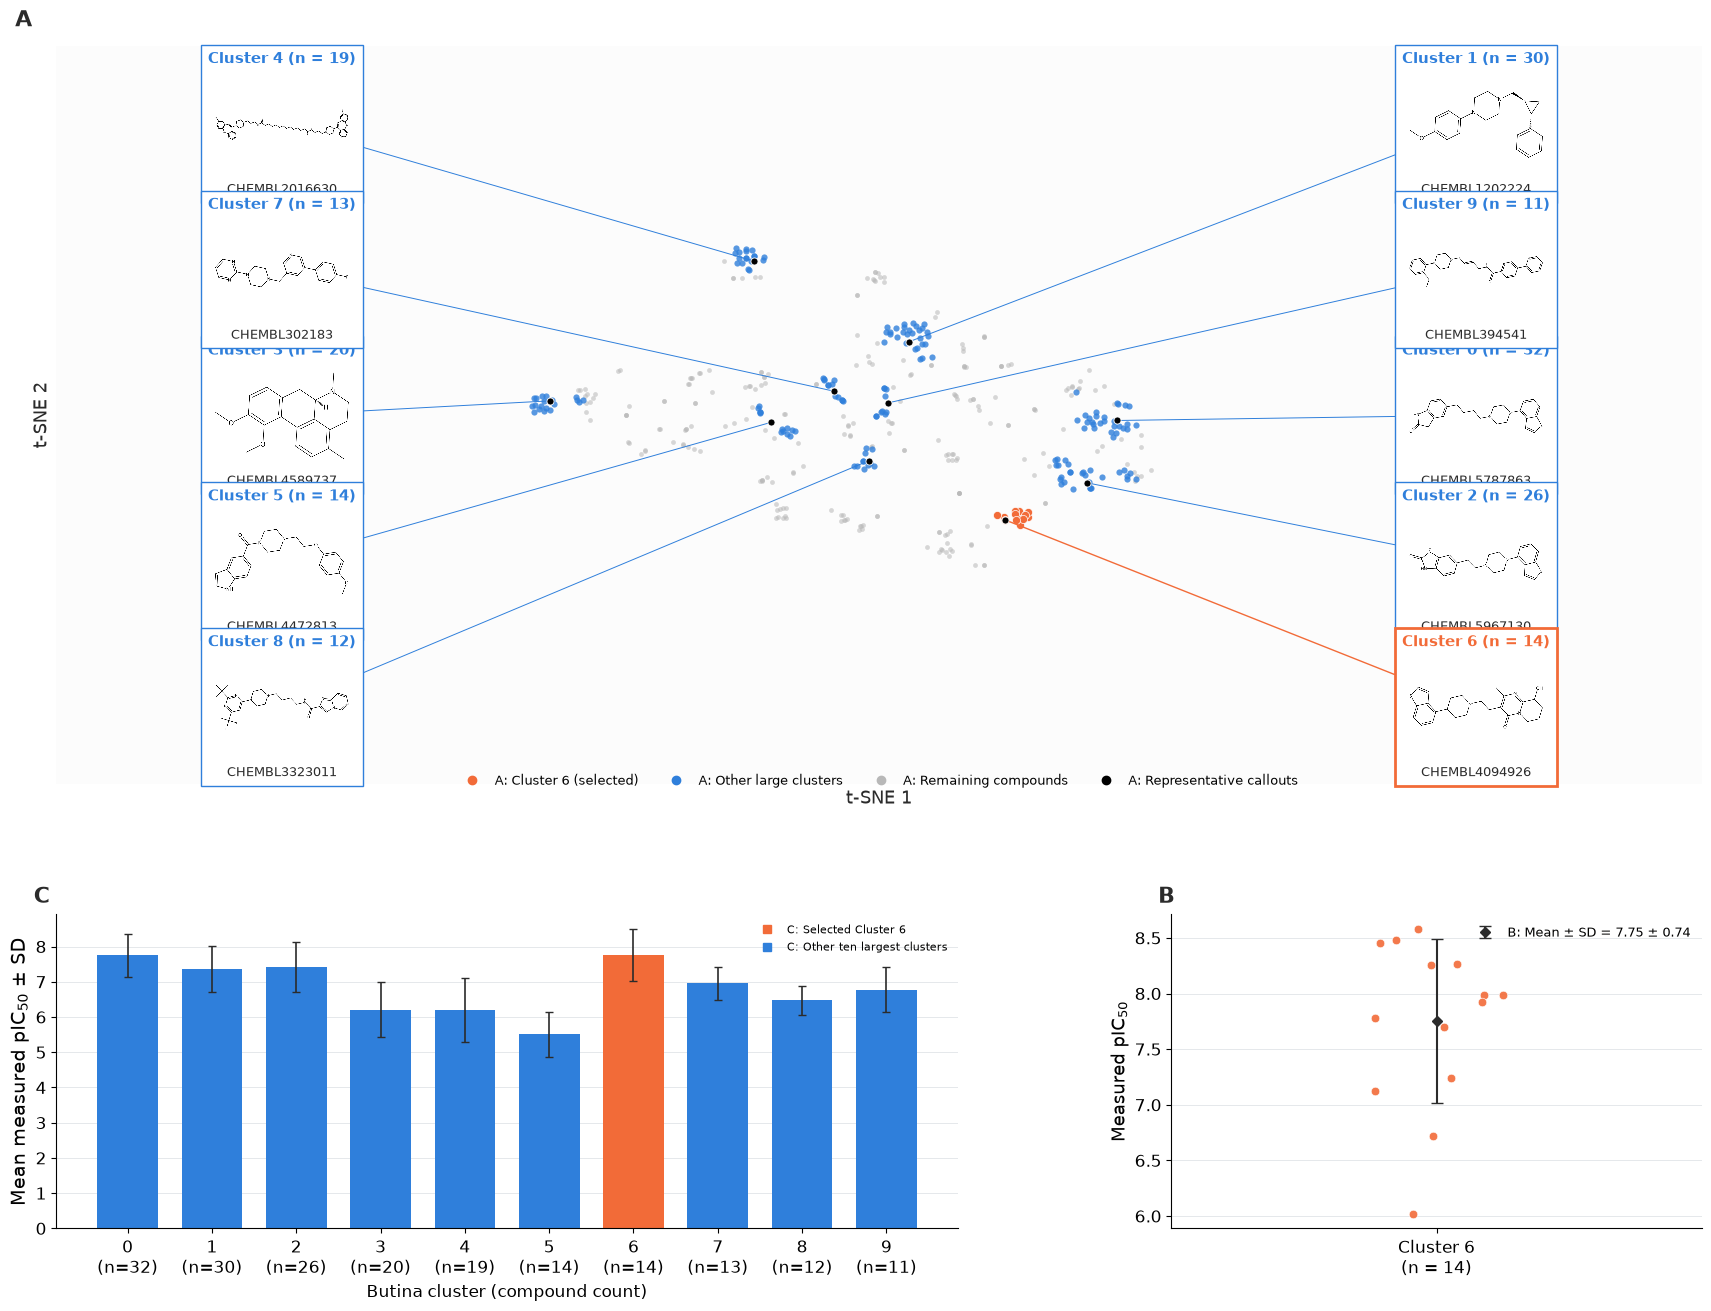

Saved PNG: /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/results/figures/figure1_tsne_clusters.png
Saved PDF: /mnt/c/Users/manup/Documents/Leiden Universiteit/LUMC/Advanced Computational Methods in Drug Discovery/Mini-Research/drd2-antagonist-ml-docking/results/figures/figure1_tsne_clusters.pdf
Panel C summary: n=14, mean=7.751, SD=0.739
Panel B cluster means: {0: 7.75, 1: 7.37, 2: 7.43, 3: 6.21, 4: 6.2, 5: 5.52, 6: 7.75, 7: 6.96, 8: 6.47, 9: 6.78}


In [10]:
fig = plt.figure(figsize=(17, 13), constrained_layout=True)
gs = fig.add_gridspec(2, 2, height_ratios=[2.35, 1], width_ratios=[1.7, 1], hspace=0.12, wspace=0.18)
axA = fig.add_subplot(gs[0, :])
axC = fig.add_subplot(gs[1, 0])
axB = fig.add_subplot(gs[1, 1])
for ax, panel in ((axA, "A"), (axB, "C"), (axC, "B")):
    ax.tick_params(axis="both", labelsize=12)
    ax.text(-0.025, 1.02, panel, transform=ax.transAxes, fontsize=16,
            fontweight="bold", color=DARK, ha="left", va="bottom", clip_on=False)

# Panel A: background points, then highlighted clusters.
other_mask = ~np.isin(cluster_labels, callouts)
axA.scatter(*xy[other_mask].T, s=12, color=GREY, alpha=0.55, linewidths=0, zorder=1)
for c in callouts:
    if c == SELECTED_CLUSTER:
        continue
    mask = cluster_labels == c
    axA.scatter(*xy[mask].T, s=20, color=cluster_colors[c], alpha=0.8, linewidths=0, zorder=2)
selected_mask = cluster_labels == SELECTED_CLUSTER
axA.scatter(*xy[selected_mask].T, s=34, color=ORANGE, edgecolor="white", linewidth=0.5, zorder=3)

# Place structure callouts in two columns to reduce overlap.
sorted_by_x = sorted(callouts, key=lambda c: xy[centroid_rows[c], 0])
half = len(sorted_by_x) // 2
left_group, right_group = sorted_by_x[:half], sorted_by_x[half:]
callout_radius = 1.72
callout_positions = {}
for side, group in ((-1, left_group), (1, right_group)):
    group = sorted(group, key=lambda c: -xy[centroid_rows[c], 1])
    ys = np.linspace(1.62, -1.62, len(group)) if len(group) > 1 else [0.0]
    for c, y in zip(group, ys):
        callout_positions[c] = (side * callout_radius, y)

for c in callouts:
    box_x, box_y = callout_positions[c]
    idx = centroid_rows[c]
    fragments = GetMolFrags(mols[idx], asMols=True)
    mol_to_draw = max(fragments, key=lambda frag: frag.GetNumHeavyAtoms())
    drawer = rdMolDraw2D.MolDraw2DCairo(850, 600)
    drawer.drawOptions().useBWAtomPalette()
    drawer.drawOptions().bondLineWidth = 3
    drawer.DrawMolecule(mol_to_draw)
    drawer.FinishDrawing()
    image = Image.open(io.BytesIO(drawer.GetDrawingText())).convert("RGBA")
    title = TextArea(f"Cluster {c} (n = {int((cluster_labels == c).sum())})",
                     textprops=dict(color=cluster_colors[c], fontsize=11, fontweight="bold"))
    compound_label = TextArea(str(df.loc[idx, COMPOUND_COL]), textprops=dict(color=DARK, fontsize=9))
    packed = VPacker(children=[title, OffsetImage(np.asarray(image), zoom=0.125), compound_label],
                     align="center", pad=2, sep=4)
    is_selected = c == SELECTED_CLUSTER
    axA.add_artist(AnnotationBbox(
        packed, xy=xy[idx], xybox=(box_x, box_y), xycoords="data", boxcoords="data",
        bboxprops=dict(ec=cluster_colors[c], fc="white", lw=2.0 if is_selected else 1.0),
        arrowprops=dict(arrowstyle="-", color=cluster_colors[c],
                        lw=1.0 if is_selected else 0.7, shrinkA=0, shrinkB=0),
        pad=0.25, zorder=5))
    axA.scatter(*xy[idx], s=26, color="black", edgecolor="white", linewidth=0.6, zorder=6)

axA.set_xlim(-callout_radius - 0.65, callout_radius + 0.65)
axA.set_ylim(-2.05, 2.05)
axA.set_facecolor("#FCFCFC")
axA.set_xticks([]); axA.set_yticks([])
for spine in axA.spines.values():
    spine.set_visible(False)
axA.set_xlabel("t-SNE 1", color=DARK, fontsize=13)
axA.set_ylabel("t-SNE 2", color=DARK, fontsize=13)
if COLOR_MODE == "theme":
    legend_handles = [
        Line2D([], [], marker="o", ls="", color=ORANGE, label=f"A: Cluster {SELECTED_CLUSTER} (selected)"),
        Line2D([], [], marker="o", ls="", color=BLUE, label="A: Other large clusters"),
        Line2D([], [], marker="o", ls="", color=GREY, label="A: Remaining compounds"),
        Line2D([], [], marker="o", ls="", color="black", label="A: Representative callouts"),
    ]
else:
    legend_handles = [Line2D([], [], marker="o", ls="", color="black", label="A: Representative callouts")]
axA.legend(handles=legend_handles, frameon=False, loc="lower center",
           bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize=9)

# Panel C: individual measured pIC50 values in the selected cluster.
selected_df = df.loc[selected_mask].copy()
activity_values = selected_df[PIC50_COL].dropna().to_numpy()
if len(activity_values) == 0:
    raise ValueError(f"No measured pIC50 values for cluster {SELECTED_CLUSTER}.")
activity_mean = activity_values.mean()
activity_sd = activity_values.std(ddof=1) if len(activity_values) > 1 else np.nan
jitter = np.random.default_rng(SEED).uniform(-0.09, 0.09, len(activity_values))
axB.scatter(jitter, activity_values, s=38, color=ORANGE, alpha=0.9,
            edgecolor="white", linewidth=0.5, zorder=3)
if np.isfinite(activity_sd):
    axB.errorbar(0, activity_mean, yerr=activity_sd, fmt="D", ms=5, color=DARK,
                 ecolor=DARK, elinewidth=1.5, capsize=4, zorder=4,
                 label=f"C: Mean ± SD = {activity_mean:.2f} ± {activity_sd:.2f}")
else:
    axB.plot(0, activity_mean, marker="D", color=DARK, label=f"C: Mean = {activity_mean:.2f}")
axB.set_ylabel("Measured pIC$_{50}$", fontsize=13)
axB.set_xticks([0]); axB.set_xticklabels([f"Cluster {SELECTED_CLUSTER}\n(n = {len(activity_values)})"])
axB.set_xlim(-0.35, 0.35)
axB.grid(axis="y", color="#D9DDE2", lw=0.6, alpha=0.8)
axB.set_axisbelow(True)
axB.legend(frameon=False, loc="best", fontsize=9)

# Panel B: mean measured pIC50 for the ten largest clusters.
cluster_order = cluster_sizes.index[:min(10, len(cluster_sizes))].tolist()
summary_rows = []
for c in cluster_order:
    vals = pd.to_numeric(df.loc[df[CLUSTER_COL] == c, PIC50_COL], errors="coerce").dropna().to_numpy()
    if len(vals):
        summary_rows.append({"cluster": c, "n": len(vals), "mean": vals.mean(),
                             "sd": vals.std(ddof=1) if len(vals) > 1 else 0.0})
summary = pd.DataFrame(summary_rows)
bar_colors = [ORANGE if c == SELECTED_CLUSTER else BLUE for c in summary["cluster"]]
x = np.arange(len(summary))
axC.bar(x, summary["mean"], color=bar_colors, width=0.72, zorder=2)
axC.errorbar(x, summary["mean"], yerr=summary["sd"], fmt="none", ecolor=DARK,
             elinewidth=1.2, capsize=3, zorder=3)
axC.set_ylabel("Mean measured pIC$_{50}$ ± SD", fontsize=14)
axC.set_xticks(x)
axC.set_xticklabels([f"{c}\n(n={n})" for c, n in zip(summary["cluster"], summary["n"])])
axC.set_xlabel("Butina cluster (compound count)", fontsize=12)
axC.grid(axis="y", color="#D9DDE2", lw=0.6, alpha=0.8)
axC.set_axisbelow(True)
axC.legend(handles=[
    Line2D([], [], marker="s", ls="", color=ORANGE, label=f"B: Selected Cluster {SELECTED_CLUSTER}"),
    Line2D([], [], marker="s", ls="", color=BLUE, label="B: Other ten largest clusters"),
], frameon=False, loc="best", fontsize=8)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_PATH, dpi=OUTPUT_DPI, bbox_inches="tight")
fig.savefig(OUTPUT_PATH.with_suffix(".pdf"), bbox_inches="tight")
plt.show()
print("Saved PNG:", OUTPUT_PATH.resolve())
print("Saved PDF:", OUTPUT_PATH.with_suffix(".pdf").resolve())
print(f"Panel C summary: n={len(activity_values)}, mean={activity_mean:.3f}, SD={activity_sd:.3f}")
print("Panel B cluster means:", {int(r.cluster): round(r.mean, 2) for r in summary.itertuples()})


## 6. Draft figure caption

**Figure 1. Chemical-space visualisation and activity of DRD2 ligand clusters.** (A) t-SNE projection of compounds based on pairwise Tanimoto distances calculated from RDKit path-based fingerprints. Existing Butina cluster assignments were retained; the largest clusters are highlighted, with representative compounds from their designated centroid rows shown as structure callouts. The selected cluster is highlighted in orange. (B) Mean measured pIC₅₀ values for the ten largest clusters, with error bars indicating standard deviation; the selected cluster is highlighted in orange. Cluster labels and sample sizes are shown on the x-axis. (C) Measured pIC₅₀ values for compounds assigned to the selected cluster. Each point represents one compound; the diamond and error bar indicate the mean ± standard deviation.

### Checks before using the figure

1. Confirm `SELECTED_CLUSTER` matches the intended cluster in the CSV; this notebook defaults to `6`.
2. Confirm `is_centroid` marks the representative compound you want to display. A centroid compound is not the same as a Bemis–Murcko scaffold consensus.
3. The t-SNE axes are for visualisation and should not be interpreted as direct quantitative measures of chemical distance.
4. The distance matrix uses \(n 	imes n\) memory, so memory use grows quadratically with compound count.
5. Confirm the fingerprint generator settings match those used in your original Butina clustering.
